In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style='whitegrid')

date_column = ['Flight Date']

birdstrikes_raw = pd.read_csv('data/birdstrikes.csv', parse_dates=date_column)
regions_raw = pd.read_csv('data/us_regions.csv')

birdstrikes = birdstrikes_raw.copy()
regions = regions_raw.copy()

print(birdstrikes.shape)
print(regions.shape)

(10000, 14)
(29, 2)


# Initial remarks

On the raw data:
- Why exactly 10000 rows? Has the data been cutoff? And if so, what is missing?
- Dataset spans from 1990-01-08 to 2002-07-25.
- No "id" column.
- 'Effect Amount of damage' has 8939 NaN.
- Lots of zeros in the three cost columns: 'Cost Other' (9928), 'Cost Repair' (9822) and 'Cost Total $' (9791). Cost Total is the other two columns added togeather.
- Speed IAS in knots has 2836 missing values
- IAS = 0 (Speed) in rows where speed cannot be 0 because 'Phase of flight' is not "Parked" (15 out of 19 "IAS = 0").
- Coyote in column 'Wildlife species' (26) don't fit when counting birdstrikes, although two of the creatures were supprisingly encountered on approach (in the air).
- There are 72 'UNKNOWN' in 'Aircraft Airline Operator'. Seems to be a lot of older non-military aircraft here, but no definate commons. Both years 1990 and 2002 are represented, so it is not a case of shift in reporting-procedures.
- 'Aircraft Airline Operator' needs to be more tidy since the particular commercial companies are at the same level as 'military' in the data set.
- 24 duplicate rows.

DataNotes:
- Always refer to birdstrike-data as "reported..." as there is likley a lot not being reported.
- Data is only US
- All of 2002 cannot be accounted for in the data.
- 'Effect Amount of damage': The military has exclusive nomenclature ('B', 'C' instead of 'minor', 'medium', 'substantial'). 
- 'Effect Amount of damage': I have real doubts about the term 'medium'.
- Refrain from drawing too big conclusions from cost as there are a lot of zeros that should probably be another number.

Questions:
- What is the state of aviation birdstrike reporting in the US during the years 1990-2002
- Sub: Trends (number of reports)
- Sub: What data that is and is not being reported (quality of reports)

### Figuring out the data (Basis for "Initial remaks")

In [113]:
birdstrikes.dtypes

Airport Name                            str
Aircraft Make Model                     str
Effect Amount of damage                 str
Flight Date                  datetime64[us]
Aircraft Airline Operator               str
Origin State                            str
Phase of flight                         str
Wildlife Size                           str
Wildlife Species                        str
Time of day                             str
Cost Other                            int64
Cost Repair                           int64
Cost Total $                          int64
Speed IAS in knots                  float64
dtype: object

In [114]:
birdstrikes.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Airport Name               10000 non-null  str           
 1   Aircraft Make Model        10000 non-null  str           
 2   Effect Amount of damage    1061 non-null   str           
 3   Flight Date                10000 non-null  datetime64[us]
 4   Aircraft Airline Operator  10000 non-null  str           
 5   Origin State               10000 non-null  str           
 6   Phase of flight            10000 non-null  str           
 7   Wildlife Size              10000 non-null  str           
 8   Wildlife Species           10000 non-null  str           
 9   Time of day                10000 non-null  str           
 10  Cost Other                 10000 non-null  int64         
 11  Cost Repair                10000 non-null  int64         
 12  Cost Total $    

**Lots of 0s in cost columns :**

In [115]:
zero = birdstrikes["Cost Other"] == 0

print(birdstrikes["Cost Other"].isna().sum())
print(birdstrikes.loc[zero].shape[0])
birdstrikes["Cost Other"].describe().round(2)

0
9928


count      10000.00
mean         424.24
std        18298.22
min            0.00
25%            0.00
50%            0.00
75%            0.00
max      1565354.00
Name: Cost Other, dtype: float64

In [116]:
zero = birdstrikes["Cost Repair"] == 0

print(birdstrikes["Cost Repair"].isna().sum())
print(birdstrikes.loc[zero].shape[0])
birdstrikes["Cost Repair"].describe().round(2)

0
9822


count      10000.00
mean        3630.29
std        97869.97
min            0.00
25%            0.00
50%            0.00
75%            0.00
max      7043545.00
Name: Cost Repair, dtype: float64

In [117]:
zero = birdstrikes["Cost Total $"] == 0

print(birdstrikes["Cost Total $"].isna().sum())
print(birdstrikes.loc[zero].shape[0])
birdstrikes["Cost Total $"].describe().round(2)

0
9791


count      10000.00
mean        4054.53
std       102135.32
min            0.00
25%            0.00
50%            0.00
75%            0.00
max      7043545.00
Name: Cost Total $, dtype: float64

In [118]:
(birdstrikes["Cost Other"] + birdstrikes["Cost Repair"] == birdstrikes["Cost Total $"]).value_counts()

True    10000
Name: count, dtype: int64

**Speed IAS in knots:** 2836 Missing values

In [119]:
print(birdstrikes["Speed IAS in knots"].isna().sum())

2836


**Speed IAS in knots = 0 :**
There are speed = 0 birdstrikes where the aircraft is parked, these make sense, but there are others where the information is clearly wrong.
The false 0s needs to be distinguished before calculations on speed.

In [120]:
birdstrikes["Speed IAS in knots"].describe()

count    7164.000000
mean      153.535176
std        43.518503
min         0.000000
25%       130.000000
50%       140.000000
75%       170.000000
max       350.000000
Name: Speed IAS in knots, dtype: float64

In [121]:
speed_zero = birdstrikes["Speed IAS in knots"] == 0

print(birdstrikes.loc[speed_zero].shape[0])
birdstrikes.loc[speed_zero].head(50)

19


,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots
276,ATLANTIC CITY INTL,F-16,NaN,1990-09-18,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,5218,5218,0.0
340,ATLANTIC CITY INTL,F-16,NaN,1990-10-15,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,0,0,0.0
341,ATLANTIC CITY INTL,F-16,NaN,1990-10-15,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,0,0,0.0
363,HONOLULU INTL ARPT,E-6,NaN,1990-10-24,MILITARY,Hawaii,Landing Roll,Medium,Unknown bird or bat,Day,0,0,0,0.0
385,BARKSDALE AIR FORCE BASE ARPT,B-52G,NaN,1990-10-27,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Day,0,0,0,0.0
562,BARKSDALE AIR FORCE BASE ARPT,B-52G,NaN,1991-05-02,MILITARY,Louisiana,Approach,Small,Cattle egret,Night,0,0,0,0.0
614,BARKSDALE AIR FORCE BASE ARPT,A-10A,NaN,1991-05-22,MILITARY,Louisiana,Take-off run,Medium,Unknown bird or bat,Dawn,0,2711,2711,0.0
954,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1991-11-06,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Day,0,0,0,0.0
1327,CHICAGO O'HARE INTL ARPT,B-767-300,NaN,1992-07-16,UNITED AIRLINES,Illinois,Take-off run,Medium,Unknown bird - medium,Day,0,0,0,0.0
1395,BARKSDALE AIR FORCE BASE ARPT,B-52G,NaN,1992-08-13,MILITARY,Louisiana,Climb,Medium,Unknown bird or bat,Night,0,0,0,0.0


In [122]:
speed_zero_not_parked = (birdstrikes["Speed IAS in knots"] == 0) & (birdstrikes["Phase of flight"] != "Parked")

print(birdstrikes.loc[speed_zero_not_parked].shape[0])
birdstrikes.loc[speed_zero_not_parked].head(50)

15


,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots
276,ATLANTIC CITY INTL,F-16,NaN,1990-09-18,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,5218,5218,0.0
340,ATLANTIC CITY INTL,F-16,NaN,1990-10-15,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,0,0,0.0
341,ATLANTIC CITY INTL,F-16,NaN,1990-10-15,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,0,0,0.0
363,HONOLULU INTL ARPT,E-6,NaN,1990-10-24,MILITARY,Hawaii,Landing Roll,Medium,Unknown bird or bat,Day,0,0,0,0.0
385,BARKSDALE AIR FORCE BASE ARPT,B-52G,NaN,1990-10-27,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Day,0,0,0,0.0
562,BARKSDALE AIR FORCE BASE ARPT,B-52G,NaN,1991-05-02,MILITARY,Louisiana,Approach,Small,Cattle egret,Night,0,0,0,0.0
614,BARKSDALE AIR FORCE BASE ARPT,A-10A,NaN,1991-05-22,MILITARY,Louisiana,Take-off run,Medium,Unknown bird or bat,Dawn,0,2711,2711,0.0
954,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1991-11-06,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Day,0,0,0,0.0
1327,CHICAGO O'HARE INTL ARPT,B-767-300,NaN,1992-07-16,UNITED AIRLINES,Illinois,Take-off run,Medium,Unknown bird - medium,Day,0,0,0,0.0
1395,BARKSDALE AIR FORCE BASE ARPT,B-52G,NaN,1992-08-13,MILITARY,Louisiana,Climb,Medium,Unknown bird or bat,Night,0,0,0,0.0


**Coyote as 'Wildlife Species' :** The 26 coyotes are certainly wildlife, but they are not birds.

In [123]:
birdstrikes["Wildlife Species"].value_counts(dropna=False)

Wildlife Species
Unknown bird - small     3572
Unknown bird - medium    3372
Unknown bird or bat       629
Unknown bird - large      436
European starling         319
Rock pigeon               232
Mourning dove             217
Canada goose              190
Red-tailed hawk           100
Ring-billed gull           87
American kestrel           83
Pacific golden-plover      65
Killdeer                   64
Mallard                    63
American robin             62
Herring gull               52
Barn owl                   47
American crow              41
Barn swallow               38
White-tailed deer          34
Turkey vulture             33
Eastern meadowlark         30
Laughing gull              29
Coyote                     26
Great blue heron           25
Zebra dove                 25
Horned lark                22
Western meadowlark         19
Cattle egret               16
Tree swallow               14
Cliff swallow              13
Blackbirds                 10
Meadowlarks            

In [124]:
coyotes = birdstrikes["Wildlife Species"] == "Coyote"

birdstrikes.loc[coyotes, "Phase of flight"].value_counts()

Phase of flight
Take-off run    12
Landing Roll    12
Approach         2
Name: count, dtype: int64

**Time of day, Wildlife Size, Phase of flight, Origin State, Flight Date and Airport Name:** Columns look alright

In [125]:
print(birdstrikes["Time of day"].isna().sum())
birdstrikes["Time of day"].value_counts(dropna=False)

0


Time of day
Day      5624
Night    3363
Dusk      584
Dawn      429
Name: count, dtype: int64

In [126]:
print(birdstrikes["Wildlife Size"].isna().sum())
birdstrikes["Wildlife Size"].value_counts(dropna=False)

0


Wildlife Size
Small     4910
Medium    4346
Large      744
Name: count, dtype: int64

In [127]:
print(birdstrikes["Phase of flight"].isna().sum())
birdstrikes["Phase of flight"].value_counts(dropna=False)

0


Phase of flight
Approach        4619
Climb           1956
Take-off run    1592
Landing Roll    1405
Descent          399
Taxi              18
Parked            11
Name: count, dtype: int64

In [128]:
print(birdstrikes["Origin State"].isna().sum())
birdstrikes["Origin State"].value_counts(dropna=False)

0


Origin State
Texas             1495
California         890
Louisiana          618
Tennessee          569
Kentucky           535
Pennsylvania       514
Illinois           505
DC                 475
New York           391
Missouri           376
Hawaii             352
New Jersey         351
North Carolina     269
Florida            246
Oregon             245
South Carolina     242
Utah               236
Georgia            211
Ohio               210
Maryland           201
Colorado           187
Massachusetts      146
Indiana            144
Nebraska           118
Arizona            111
Minnesota          103
Washington         103
Oklahoma            83
Michigan            74
Name: count, dtype: int64

In [129]:
print(birdstrikes["Flight Date"].isna().sum())
birdstrikes["Flight Date"].describe()

0


count                         10000
mean     1997-03-20 11:22:16.320000
min             1990-01-08 00:00:00
25%             1994-04-30 18:00:00
50%             1997-08-29 00:00:00
75%             2000-05-21 06:00:00
max             2002-07-25 00:00:00
Name: Flight Date, dtype: object

In [130]:
print(birdstrikes["Airport Name"].isna().sum())
print(birdstrikes["Airport Name"].nunique())
birdstrikes["Airport Name"].value_counts(dropna=False).sort_index()

0
50


Airport Name
ATLANTA INTL                              211
ATLANTIC CITY INTL                         86
AUSTIN-BERGSTROM INTL                     144
BALTIMORE WASH INTL                       201
BARKSDALE AIR FORCE BASE ARPT             435
CHARLESTON AFB/INTL ARPT                  242
CHARLOTTE/DOUGLAS INTL ARPT               269
CHICAGO MIDWAY INTL ARPT                   75
CHICAGO O'HARE INTL ARPT                  430
CINCINNATI/NORTHERN KENTUCKY INTL ARPT    263
CLEVELAND-HOPKINS INTL ARPT                98
DALLAS/FORT WORTH INTL ARPT               908
DENVER INTL AIRPORT                       187
DETROIT METRO WAYNE COUNTY ARPT            74
EPPLEY AIRFIELD                           118
FORT LAUDERDALE/HOLLYWOOD INTL             93
GEORGE BUSH INTERCONTINENTAL              134
GREATER PITTSBURGH                        289
HONOLULU INTL ARPT                        135
HOUSTON-HOBBY                             151
INDIANAPOLIS INTL                         144
JOHN F KENNEDY INTL  

**Aircraft Make Model**

Could be different nomenclatures hiding here

In [131]:
print(birdstrikes["Aircraft Make Model"].isna().sum())
print(birdstrikes["Aircraft Make Model"].nunique())
birdstrikes["Aircraft Make Model"].value_counts(dropna=False).sort_index()

0
225


Aircraft Make Model
A-10A      20
A-300     119
A-310      27
A-319     106
A-320     224
         ... 
T-38A       8
T-38C       1
T-43A       1
TC-18F      2
VC-137      1
Name: count, Length: 225, dtype: int64

**Effect Amount of damage**

- 8939 NaN
- "B" and "C" seems to be of a different nomenclature than the other values

In [132]:
birdstrikes["Effect Amount of damage"].value_counts(dropna=False)

Effect Amount of damage
NaN            8939
Minor           549
Substantial     311
Medium          186
C                14
B                 1
Name: count, dtype: int64

In [133]:
grouped_by_damage_nom = birdstrikes.groupby("Effect Amount of damage").agg(operator = ("Aircraft Airline Operator", "nunique"))

grouped_by_damage_nom

,operator
Effect Amount of damage,
B,1
C,1
Medium,32
Minor,41
Substantial,34


In [134]:
military = birdstrikes[birdstrikes["Aircraft Airline Operator"] == "MILITARY"]

military["Effect Amount of damage"].value_counts()

Effect Amount of damage
C    14
B     1
Name: count, dtype: int64

In [135]:
civil = birdstrikes[birdstrikes["Aircraft Airline Operator"] != "MILITARY"]

civil["Effect Amount of damage"].value_counts()

Effect Amount of damage
Minor          549
Substantial    311
Medium         186
Name: count, dtype: int64

**Aircraft Airline Operators**

- There are 72 UNKNOWN

- GOVERNMENT (15) and MILITARY (829) does not seem to be overlapping categories

- PRIVATELY OWNED (36), BUSINESS (371): Slightly wierd categorization as they seem to refer to ownership structure rather than operation. Both of these are commonly refered to as 'General Aviation'



In [136]:
birdstrikes["Aircraft Airline Operator"].value_counts(dropna=False)

Aircraft Airline Operator
AMERICAN AIRLINES                 2171
US AIRWAYS*                       1084
DELTA AIR LINES                    865
SOUTHWEST AIRLINES                 844
MILITARY                           829
UNITED AIRLINES                    534
BUSINESS                           371
FEDEX EXPRESS                      365
AMERICA WEST AIRLINES              275
NORTHWEST AIRLINES                 256
UPS AIRLINES                       223
AMERICAN EAGLE AIRLINES            223
CONTINENTAL AIRLINES               187
ALOHA AIRLINES                     184
TRANS WORLD AIRLINES               163
ATLANTIC COAST AIRLINES            138
COMAIR AIRLINES                    113
EXPRESSJET (CONTINENTAL EXPRS)     106
ALASKA AIRLINES                    102
HORIZON AIR                        102
HAWAIIAN AIR                        97
ABX AIR                             76
UNKNOWN                             72
AIR CANADA                          69
SKYWEST AIRLINES                    68

In [137]:
gov = birdstrikes["Aircraft Airline Operator"] == "GOVERNMENT"

birdstrikes.loc[gov].head(15)

,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots
120,ATLANTIC CITY INTL,CV-580,NaN,1990-06-27,GOVERNMENT,New Jersey,Landing Roll,Medium,Unknown bird - medium,Day,0,0,0,40.0
478,RONALD REAGAN WASHINGTON NATL,CITATION II,NaN,1991-01-24,GOVERNMENT,DC,Approach,Small,European starling,Day,0,0,0,110.0
509,SEATTLE-TACOMA INTL,B-727-200,NaN,1991-03-19,GOVERNMENT,Washington,Take-off run,Small,Barn owl,Night,0,0,0,120.0
516,BALTIMORE WASH INTL,AEROS SA365,NaN,1991-03-24,GOVERNMENT,Maryland,Climb,Medium,Unknown bird - medium,Night,0,0,0,90.0
2280,ATLANTIC CITY INTL,CV-580,NaN,1993-10-22,GOVERNMENT,New Jersey,Landing Roll,Medium,Herring gull,Day,0,0,0,NaN
2374,NEW ORLEANS INTL,B-727-100,NaN,1994-01-04,GOVERNMENT,Louisiana,Approach,Small,Killdeer,Day,0,0,0,NaN
2642,ATLANTIC CITY INTL,BELL-212,NaN,1994-07-19,GOVERNMENT,New Jersey,Parked,Small,Rock pigeon,Day,0,0,0,0.0
3769,ATLANTIC CITY INTL,GULFAERO III,NaN,1996-01-17,GOVERNMENT,New Jersey,Take-off run,Medium,Unknown bird - medium,Day,0,0,0,NaN
3915,LIHUE ARPT,LOCKHEED C-130,Medium,1996-05-14,GOVERNMENT,Hawaii,Take-off run,Medium,Unknown bird - medium,Day,0,0,0,NaN
6346,LIHUE ARPT,LOCKHEED C-130,NaN,1999-02-23,GOVERNMENT,Hawaii,Climb,Small,Zebra dove,Day,0,0,0,NaN


In [138]:
mil = birdstrikes["Aircraft Airline Operator"] == "MILITARY"

birdstrikes.loc[mil, "Aircraft Make Model"].value_counts()

Aircraft Make Model
KC-10A     213
B-52H      127
C-17A      109
C-141B      74
KC-135      36
C-130H      32
C-141       23
KC-135E     22
B-52G       22
C-130E      22
A-10A       20
KC-135R     17
T-1A         9
T-38A        8
B-52         7
F-16         7
F-16C        6
E-6          5
F-15         5
C-135B       5
C-21A        5
C-130        4
C-9          4
E-4B         3
C-135        3
EC-135       3
T-37B        3
P-3          3
C-135C       2
C-5          2
TC-18F       2
C-5A         2
HC-130P      2
E-3C         2
F-15A        2
A-7          1
C-137C       1
OA-10A       1
DC-9         1
T-43A        1
F-15B        1
E-3          1
MC-130P      1
EC-135E      1
C-135E       1
F-16A        1
F-15C        1
T-38C        1
RC-135W      1
VC-137       1
EC-130E      1
C-5B         1
B-1B         1
Name: count, dtype: int64

In [139]:
priv = birdstrikes["Aircraft Airline Operator"] == "PRIVATELY OWNED"

birdstrikes.loc[priv, "Aircraft Make Model"].value_counts()

Aircraft Make Model
PA-28           7
C-172           4
C-182 SKYLAN    4
PA-31 NAVAJO    3
C-414           2
BE-58  BARON    2
PA-32           2
BE-200 KING     2
PA-46 MALIBU    1
BE-55  BARON    1
BE-90  KING     1
DA-10 FALCON    1
C-152           1
GRUMAMER AA1    1
C-177           1
PA-34 SENECA    1
C-150           1
C-421           1
Name: count, dtype: int64

In [140]:
bis = birdstrikes["Aircraft Airline Operator"] == "BUSINESS"

birdstrikes.loc[bis, "Aircraft Make Model"].value_counts()

Aircraft Make Model
C-560                20
CITATION II          17
LEARJET-35           17
C-650                12
HAWKER-SDLY HS125    11
                     ..
GULFAERO III          1
GRUMMAN GA7           1
CHALLENGER 300        1
LEARJET-45            1
CITATION X            1
Name: count, Length: 107, dtype: int64

In [141]:
unknown = birdstrikes["Aircraft Airline Operator"] == "UNKNOWN"

birdstrikes.loc[unknown, "Aircraft Make Model"].value_counts()

Aircraft Make Model
B-737-300       7
MD-80           6
B-757-200       4
BA-31 JETSTR    4
B-727           3
PA-31 NAVAJO    3
C-560           3
DC-9            3
B-737           3
EMB-120         2
BE-200 KING     2
SAAB-340        2
ATR-42          2
BE-58  BARON    1
PA-23-250       1
IAI ASTRA JT    1
STINSON 108     1
MD-88           1
G-159           1
B-737-500       1
BELLANCA 260    1
B-767-300       1
C-441 CONQUE    1
C-650           1
SA226 TC        1
DC-9-50         1
MD-83           1
C-172           1
PA-60 600       1
C-185 SKYWAG    1
MU2             1
HAWKER 800      1
BE-36           1
BE-400 BJET     1
B-737-200       1
MOONEY UNKN     1
C-208           1
BE-95           1
CL-RJ100/200    1
DORNIER 328     1
DC-8-61         1
Name: count, dtype: int64

In [142]:
unknown = birdstrikes["Aircraft Airline Operator"] == "UNKNOWN"

birdstrikes.loc[unknown, "Flight Date"].describe()

count                     72
mean     1995-09-14 23:20:00
min      1990-04-20 00:00:00
25%      1991-10-05 00:00:00
50%      1996-02-02 00:00:00
75%      1998-06-12 06:00:00
max      2002-07-15 00:00:00
Name: Flight Date, dtype: object

**No empty columns:**

In [143]:
empty = birdstrikes.columns[birdstrikes.isna().all()]

print(len(empty))
print(list(empty))

0
[]


**24 duplicates**

In [144]:
print(birdstrikes.duplicated().sum())

24


In [145]:
birdstrikes[birdstrikes.duplicated(keep=False)].head(14)

,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots
340,ATLANTIC CITY INTL,F-16,NaN,1990-10-15,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,0,0,0.0
341,ATLANTIC CITY INTL,F-16,NaN,1990-10-15,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,0,0,0.0
1113,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1992-04-14,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,150.0
1114,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1992-04-14,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,150.0
1131,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1992-04-23,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,140.0
1132,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1992-04-23,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,140.0
1267,GREATER PITTSBURGH,DC-9-30,NaN,1992-06-15,US AIRWAYS*,Pennsylvania,Climb,Small,Unknown bird - small,Day,0,0,0,150.0
1268,GREATER PITTSBURGH,DC-9-30,NaN,1992-06-15,US AIRWAYS*,Pennsylvania,Climb,Small,Unknown bird - small,Day,0,0,0,150.0
1813,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1993-04-28,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,180.0
1814,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1993-04-28,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,180.0


# Cleaning and changes

Cleaning plan (in order):
1. Merge with us_regions.csv on 'Origin State' as new column 'Region'.
2. 24 duplicate rows -> Remove rows (They only make the data worse). But since we do not have a unique identifier for the incidents we could be removing 'False negatives'. There could for example be a situation where two military aircraft flying in formation encounters the same flock of birds resulting in two identical reports.
3. Coyote in column 'Wildlife species' (26) -> Remove rows (Coyotes are not birds).
4. IAS = 0 when aircraft is not parked (15) -> Change to NaN (Both pieces of information cannot be true at the same time and there is no missing values in 'Phase of flight').
5. Lots of 0s in Cost columns: 'Cost Other', 'Cost Repair' and 'Cost Total $ -> Add column 'Total Reported Costs' where 0 becomes NaN.
6. Add ´Operation type' column to distiguish airlines from military, government and unknown.
7. Add 'species identified' column to make it easier for counting.

Not changed:
- 'Effect Amount of damage' 8939 NaN (We can not guess).
- 72 'UNKNOWN' in 'Aircraft Airline Operator' (We can not guess).
- No "id" column. Adding an "id" column does not help now, but it would have been useful if it was in the raw data as it would have differentiated duplicated incident id's.
from rows with the same information.
- Speed IAS in knots, 2836 missing values (It is good to have missing values here rather than suspicious 0 values).
- US AIRWAYS will continue to be called US AIRWAYS* as it makes no difference to the final product.
- Titles will not be changed as it makes no difference to the final product.
- 'Effect Amount of damage': The military has exclusive nomenclature ('B', 'C'). No changes will be made as it would be guesswork.
- 'Effect Amount of damage': For civil aircraft the term 'medium' occurs. This does not pass the smell-test for "defined terms in avaiation". Could be a product of bad automation. I will do nothing about it since I can't be sure, but for this reason I will stay away from digging too deep in this column in my final analysis.

### 1. Merge

In [146]:
merged = birdstrikes.merge(regions, on="Origin State", how="left", validate="many_to_one")

print(merged.shape)
merged.sort_index().head(10)

(10000, 15)


,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots,Region
0,BARKSDALE AIR FORCE BASE ARPT,T-38A,NaN,1990-01-08,MILITARY,Louisiana,Climb,Large,Turkey vulture,Day,0,0,0,300.0,South
1,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-01-09,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,200.0,South
2,BARKSDALE AIR FORCE BASE ARPT,B-52,NaN,1990-01-11,MILITARY,Louisiana,Take-off run,Medium,Unknown bird or bat,Day,0,0,0,130.0,South
3,NEW ORLEANS INTL,B-737-300,Substantial,1990-01-11,SOUTHWEST AIRLINES,Louisiana,Take-off run,Small,Rock pigeon,Day,0,0,0,140.0,South
4,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-01-12,MILITARY,Louisiana,Climb,Medium,Unknown bird or bat,Day,0,0,0,160.0,South
5,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-02-02,MILITARY,Louisiana,Take-off run,Medium,Unknown bird or bat,Day,0,0,0,180.0,South
6,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-02-06,MILITARY,Louisiana,Climb,Medium,Unknown bird or bat,Dusk,0,0,0,140.0,South
7,WASHINGTON DULLES INTL ARPT,B-727,NaN,1990-02-22,FEDEX EXPRESS,DC,Approach,Large,Unknown bird - large,Night,0,0,0,190.0,South
8,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-03-01,MILITARY,Louisiana,Climb,Medium,Unknown bird or bat,Day,0,0,0,180.0,South
9,BARKSDALE AIR FORCE BASE ARPT,B-52,NaN,1990-03-02,MILITARY,Louisiana,Take-off run,Medium,Unknown bird or bat,Dusk,0,0,0,130.0,South


In [147]:
merged["Region"].value_counts(dropna=False)

Region
South        4944
West         2124
Midwest      1530
Northeast    1402
Name: count, dtype: int64

In [148]:
birdstrikes = merged

print(birdstrikes.shape)
birdstrikes.info()

(10000, 15)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Airport Name               10000 non-null  str           
 1   Aircraft Make Model        10000 non-null  str           
 2   Effect Amount of damage    1061 non-null   str           
 3   Flight Date                10000 non-null  datetime64[us]
 4   Aircraft Airline Operator  10000 non-null  str           
 5   Origin State               10000 non-null  str           
 6   Phase of flight            10000 non-null  str           
 7   Wildlife Size              10000 non-null  str           
 8   Wildlife Species           10000 non-null  str           
 9   Time of day                10000 non-null  str           
 10  Cost Other                 10000 non-null  int64         
 11  Cost Repair                10000 non-null  int64         
 12  Cost

### 2. Drop duplicate rows

In [149]:
print(birdstrikes.duplicated().sum())

24


In [150]:
birdstrikes = birdstrikes.drop_duplicates()
print(birdstrikes.duplicated().sum())
print(birdstrikes.shape)

0
(9976, 15)


### 3. Drop rows with 'Coyote' as 'Wildlife species'

In [151]:
coyotes = (birdstrikes["Wildlife Species"] == "Coyote").sum()
print(coyotes)

26


In [152]:
birdstrikes = birdstrikes[birdstrikes["Wildlife Species"] != "Coyote"]
coyotes = (birdstrikes["Wildlife Species"] == "Coyote").sum()
print(coyotes)
birdstrikes.shape

0


(9950, 15)

### 4. Change 'Speed IAS in knots' to NaN if IAS = 0 and aircraft is not parked

In [153]:
speed_zero_not_parked = (birdstrikes["Speed IAS in knots"] == 0) & (birdstrikes["Phase of flight"] != "Parked")

print(birdstrikes.loc[speed_zero_not_parked].shape[0])
print(birdstrikes["Speed IAS in knots"].isna().sum())

14
2807


In [154]:
birdstrikes.loc[(birdstrikes["Speed IAS in knots"] == 0) & (birdstrikes["Phase of flight"] != "Parked"), "Speed IAS in knots"] = np.nan

speed_zero_not_parked = (birdstrikes["Speed IAS in knots"] == 0) & (birdstrikes["Phase of flight"] != "Parked")

print(birdstrikes.loc[speed_zero_not_parked].shape[0])
print(birdstrikes["Speed IAS in knots"].isna().sum())
birdstrikes["Speed IAS in knots"].describe()

0
2821


count    7129.000000
mean      153.892271
std        43.017522
min         0.000000
25%       130.000000
50%       140.000000
75%       170.000000
max       350.000000
Name: Speed IAS in knots, dtype: float64

In [155]:
birdstrikes.shape

(9950, 15)

### 5. Add column 'Total Reported Costs' where 0 -> NaN

But first some checks

In [156]:
cost_grouped_by_operator = birdstrikes.groupby("Aircraft Airline Operator").agg(cost = ("Cost Total $", "mean"))

cost_grouped_by_operator.round(0)

,cost
Aircraft Airline Operator,
ABX AIR,94.0
AIR CANADA,4484.0
AIR WISCONSIN AIRLINES,20.0
AIRTRAN AIRWAYS,55.0
ALASKA AIRLINES,3476.0
ALLEGHENYAIRLINES,59.0
ALOHA AIRLINES,9.0
AMERICA WEST AIRLINES,544.0
AMERICAN AIRLINES,1013.0


In [157]:
cost_grouped_by_damage = birdstrikes.groupby("Effect Amount of damage").agg(mean_cost = ("Cost Total $", "mean"))

cost_grouped_by_damage.round(0)

,mean_cost
Effect Amount of damage,
B,636405.0
C,63218.0
Medium,5336.0
Minor,4937.0
Substantial,112736.0


In [158]:
cost_above_zero = birdstrikes["Cost Total $"] > 0

print(birdstrikes["Cost Total $"].isna().sum())
cost_above_zero.value_counts()

0


Cost Total $
False    9741
True      209
Name: count, dtype: int64

In [159]:
birdstrikes["Cost Total $"].describe().round(2)

count       9950.00
mean        4074.90
std       102391.24
min            0.00
25%            0.00
50%            0.00
75%            0.00
max      7043545.00
Name: Cost Total $, dtype: float64

In [160]:
birdstrikes["Total Reported Costs"] = birdstrikes["Cost Total $"].astype(int)

birdstrikes["Total Reported Costs"] = birdstrikes["Total Reported Costs"].replace(0, np.nan)

print(birdstrikes.shape)
birdstrikes["Total Reported Costs"].describe().round(2)

(9950, 16)


count        209.00
mean      193996.54
std       681502.00
min           35.00
25%         2744.00
50%        23325.00
75%        89453.00
max      7043545.00
Name: Total Reported Costs, dtype: float64

### 6. Add column 'Operation Type' to cluster airlines under one category (COMMERCIAL), and cluster business and privately owned to form (GA) (General Aviation)

In [161]:
operator = birdstrikes["Aircraft Airline Operator"]

birdstrikes["Operation Type"] = operator
birdstrikes.loc[operator.isin(["BUSINESS", "PRIVATELY OWNED"]), "Operation Type"] = "GA"
birdstrikes.loc[~operator.isin(["MILITARY", "GOVERNMENT", "UNKNOWN", "BUSINESS", "PRIVATELY OWNED"]), "Operation Type"] = "COMMERCIAL"

print(birdstrikes.shape)
birdstrikes["Operation Type"].value_counts()

(9950, 17)


Operation Type
COMMERCIAL    8647
MILITARY       813
GA             404
UNKNOWN         71
GOVERNMENT      15
Name: count, dtype: int64

### 7. Add column 'Species Identified'

In [162]:
print(birdstrikes.shape)

unidentified = [
    "Unknown bird - small",
    "Unknown bird - medium",
    "Unknown bird or bat",
    "Unknown bird - large",
]

birdstrikes["Species Identified"] = ~birdstrikes["Wildlife Species"].isin(unidentified)

print(birdstrikes.shape)
birdstrikes["Species Identified"].value_counts(dropna=False)

(9950, 17)
(9950, 18)


Species Identified
False    7987
True     1963
Name: count, dtype: int64

# Observations

### Extreme costs
- 7 million USD is a lot, even in aviation terms. But it is not clear that it is a faulty value.
- I cannot find any offical incident reports as birdstrikes don't seem to warrant them.

In [163]:
birdstrikes.sort_values("Total Reported Costs", ascending=False).head(10)

,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots,Region,Total Reported Costs,Operation Type,Species Identified
5424,AUSTIN-BERGSTROM INTL,B-727-200,Substantial,1998-02-24,FEDEX EXPRESS,Texas,Climb,Large,Unknown bird - large,Dawn,0,7043545,7043545,190.0,South,7043545.0,COMMERCIAL,False
3496,LAGUARDIA NY,A-320,Substantial,1995-09-19,NORTHWEST AIRLINES,New York,Landing Roll,Large,Canada goose,Night,762315,3049261,3811576,125.0,Northeast,3811576.0,COMMERCIAL,True
8634,NEWARK LIBERTY INTL ARPT,A-300,Substantial,2001-06-08,UPS AIRLINES,New Jersey,Approach,Large,Canada goose,Dawn,0,3644483,3644483,136.0,Northeast,3644483.0,COMMERCIAL,True
7284,PHILADELPHIA INTL,A-320,Substantial,2000-02-22,US AIRWAYS*,Pennsylvania,Climb,Large,Canada goose,Day,26727,3340917,3367644,180.0,Northeast,3367644.0,COMMERCIAL,True
6420,CHICAGO O'HARE INTL ARPT,B-737-200,Substantial,1999-04-05,UNITED AIRLINES,Illinois,Take-off run,Medium,Red-tailed hawk,Day,0,1715077,1715077,NaN,Midwest,1715077.0,COMMERCIAL,True
2680,CHICAGO O'HARE INTL ARPT,B-757-200,Substantial,1994-08-03,UNITED AIRLINES,Illinois,Take-off run,Large,Canada goose,Dusk,1565354,0,1565354,NaN,Midwest,1565354.0,COMMERCIAL,True
3580,SAN FRANCISCO INTL ARPT,DA-900,Substantial,1995-10-10,BUSINESS,California,Climb,Large,Unknown bird - large,Dusk,4574,1524631,1529205,195.0,West,1529205.0,GA,False
1612,JOHN F KENNEDY INTL,B-747-400,Substantial,1992-10-24,JAPAN AIRLINES,New York,Take-off run,Medium,Herring gull,Day,0,1237569,1237569,NaN,Northeast,1237569.0,COMMERCIAL,True
8377,PORTLAND INTL (OR),DHC8 DASH 8,Substantial,2001-03-04,HORIZON AIR,Oregon,Climb,Small,Rock pigeon,Day,0,979455,979455,NaN,West,979455.0,COMMERCIAL,True
7483,LOS ANGELES INTL,SAAB-340,Substantial,2000-05-15,AMERICAN EAGLE AIRLINES,California,Take-off run,Small,Rock pigeon,Day,133637,668183,801820,100.0,West,801820.0,COMMERCIAL,True


### Even the highest recorded speed is far below cruise speed (between approx. 470 and 520 knots for Boeing 727)
- 'Speed IAS in knots' is a fairly well reported value with only about 28% missing (2821)
- Probable explanation: A lot of airplanes cruise at far higher altitudes than birds. This is backed up by the fact that there are no reports with 'Phase of flight' = "Cruise"

In [164]:
print(birdstrikes["Speed IAS in knots"].isna().sum())
print(((birdstrikes["Speed IAS in knots"].isna().sum() / birdstrikes.shape[0]) * 100).round(2))
birdstrikes.sort_values("Speed IAS in knots", ascending=False).head(3)

2821
28.35


,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots,Region,Total Reported Costs,Operation Type,Species Identified
138,SALT LAKE CITY INTL,B-727,Minor,1990-07-11,DELTA AIR LINES,Utah,Descent,Large,Unknown bird - large,Day,0,0,0,350.0,West,NaN,COMMERCIAL,False
9908,CINCINNATI/NORTHERN KENTUCKY INTL ARPT,B-727-200,NaN,2002-07-07,FEDEX EXPRESS,Kentucky,Descent,Medium,Unknown bird - medium,Day,0,0,0,340.0,South,NaN,COMMERCIAL,False
1763,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1993-04-08,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,340.0,South,NaN,MILITARY,False


In [165]:
birdstrikes["Phase of flight"].value_counts()

Phase of flight
Approach        4602
Climb           1953
Take-off run    1580
Landing Roll    1388
Descent          399
Taxi              18
Parked            10
Name: count, dtype: int64

### In the lower extremes in speed the values add upp well to 'Phase of flight'
- Note: I have changed 14 'Speed IAS in knots' values to NaN where the 'Phase of flight' was "Parked" but the speed was not 0

In [166]:
birdstrikes.sort_values("Speed IAS in knots", ascending=True).head(10)

,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots,Region,Total Reported Costs,Operation Type,Species Identified
2104,NASHVILLE INTL,FOKKER F100,NaN,1993-08-24,AMERICAN AIRLINES,Tennessee,Parked,Small,Unknown bird - small,Day,0,0,0,0.0,South,NaN,COMMERCIAL,False
9681,BARKSDALE AIR FORCE BASE ARPT,A-10A,NaN,2002-05-13,MILITARY,Louisiana,Parked,Medium,Unknown bird or bat,Dawn,0,0,0,0.0,South,NaN,MILITARY,False
8549,PHOENIX SKY HARBOR,B-737-300,NaN,2001-05-08,AMERICA WEST AIRLINES,Arizona,Parked,Small,Unknown bird - small,Dusk,0,0,0,0.0,West,NaN,COMMERCIAL,False
2642,ATLANTIC CITY INTL,BELL-212,NaN,1994-07-19,GOVERNMENT,New Jersey,Parked,Small,Rock pigeon,Day,0,0,0,0.0,Northeast,NaN,GOVERNMENT,True
9126,CHARLESTON AFB/INTL ARPT,C-17A,NaN,2001-09-28,MILITARY,South Carolina,Taxi,Small,Mourning dove,Day,0,0,0,7.0,South,NaN,MILITARY,True
4989,WASHINGTON DULLES INTL ARPT,BA-41 JETSTR,NaN,1997-08-26,ATLANTIC COAST AIRLINES,DC,Landing Roll,Small,Unknown bird - small,Day,0,0,0,8.0,South,NaN,COMMERCIAL,False
285,MINETA SAN JOSE INTL,AEROS 350,NaN,1990-09-21,BUSINESS,California,Taxi,Small,Unknown bird - small,Day,0,0,0,10.0,West,NaN,GA,False
2035,LOS ANGELES INTL,DA-20 FALCON,Substantial,1993-08-04,BUSINESS,California,Take-off run,Medium,Red-tailed hawk,Night,964,144645,145609,15.0,West,145609.0,GA,True
3832,MEMPHIS INTL,C-141B,NaN,1996-03-21,MILITARY,Tennessee,Take-off run,Medium,Unknown bird or bat,Dusk,0,0,0,15.0,South,NaN,MILITARY,False
3398,PORT COLUMBUS INTL,B-737-200,NaN,1995-08-09,US AIRWAYS*,Ohio,Take-off run,Small,Unknown bird - small,Night,0,0,0,20.0,Midwest,NaN,COMMERCIAL,False


### Of the 10 top speed strikes, none of the top 9 have reported costs, even when sorting for the ones that have reported damage.
- It seems that costs are not often reported, 9741 values are 0 or missning (out of 9950 rows).
- Possible explanation: When the birdstrike is first reported the cost is not known and there is no routine to update the report once the cost is known.

In [167]:
print(birdstrikes["Total Reported Costs"].isna().sum())
birdstrikes[birdstrikes["Effect Amount of damage"].notna()].sort_values("Speed IAS in knots", ascending=False).head(10)

9741


,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots,Region,Total Reported Costs,Operation Type,Species Identified
138,SALT LAKE CITY INTL,B-727,Minor,1990-07-11,DELTA AIR LINES,Utah,Descent,Large,Unknown bird - large,Day,0,0,0,350.0,West,NaN,COMMERCIAL,False
1013,MEMPHIS INTL,B-737,Substantial,1991-12-12,US AIRWAYS*,Tennessee,Descent,Large,Unknown bird - large,Night,0,0,0,320.0,South,NaN,COMMERCIAL,False
1760,LOUISVILLE INTL ARPT,B-747-1/200,Minor,1993-04-07,UPS AIRLINES,Kentucky,Climb,Large,Unknown bird - large,Night,0,0,0,320.0,South,NaN,COMMERCIAL,False
1466,AUSTIN-BERGSTROM INTL,B-737-300,Minor,1992-09-04,SOUTHWEST AIRLINES,Texas,Descent,Small,Unknown bird - small,Night,0,0,0,320.0,South,NaN,COMMERCIAL,False
270,LOS ANGELES INTL,B-737-200,Minor,1990-09-16,AMERICA WEST AIRLINES,California,Climb,Medium,Unknown bird - medium,Day,0,0,0,320.0,West,NaN,COMMERCIAL,False
4107,ATLANTA INTL,B-737-200,Minor,1996-08-13,DELTA AIR LINES,Georgia,Climb,Medium,Unknown bird - medium,Day,0,0,0,320.0,South,NaN,COMMERCIAL,False
5541,GEORGE BUSH INTERCONTINENTAL,B-737-300,Medium,1998-05-01,UNKNOWN,Texas,Climb,Medium,Unknown bird - medium,Night,0,0,0,320.0,South,NaN,UNKNOWN,False
3585,NEW ORLEANS INTL,B-737-200,Minor,1995-10-11,US AIRWAYS*,Louisiana,Descent,Large,Unknown bird - large,Day,0,0,0,310.0,South,NaN,COMMERCIAL,False
3890,HOUSTON-HOBBY,B-737-500,Medium,1996-05-05,SOUTHWEST AIRLINES,Texas,Descent,Large,Unknown bird - large,Dusk,0,0,0,300.0,South,NaN,COMMERCIAL,False
6523,CHICAGO O'HARE INTL ARPT,B-757-200,Substantial,1999-05-19,UNITED AIRLINES,Illinois,Climb,Medium,Herring gull,Day,0,104002,104002,300.0,Midwest,104002.0,COMMERCIAL,True


### Reporting of damage is quite low, but higher than reporting of costs
- 'Effect Amount of damage' has 8892 missing values out of 9950
- Possible explanation: A general assesment of the damage comes earlier in the process than the exact cost of the incident, this could make damage a better fit with the reporting routines than costs.

In [168]:
print(birdstrikes["Effect Amount of damage"].isna().sum())

8892


### Size seems to matter to cost
But we have to take into account that costs are very likley underreported

In [169]:
grouped_by_size = (birdstrikes.groupby("Wildlife Size")["Total Reported Costs"]
                   .agg(["count", "sum", "mean", "median"]))

grouped_by_size.round()

,count,sum,mean,median
Wildlife Size,,,,
Large,62,26253787.0,423448.0,52084.0
Medium,94,8679302.0,92333.0,14026.0
Small,53,5612187.0,105890.0,4339.0


### Discription of the damage seems to follow the avarage cost, both on mean and median values

- Excluded: 14 values from military aircraft since they report in a different nomenclature.
- Again, very few cost values
- Note: I cannot find any reference to 'Medium' damage. It is possible that this term is not in any official nomenclature for reporting aircraft damage, but there are 186 instances of the term in the data.

In [170]:
not_mil = birdstrikes["Operation Type"] != "MILITARY"

grouped_by_damage = (birdstrikes[not_mil].groupby("Effect Amount of damage")["Total Reported Costs"]
                   .agg(["count", "sum", "mean", "median"])
                   .sort_values("median", ascending=False))

grouped_by_damage.round()

,count,sum,mean,median
Effect Amount of damage,,,,
Substantial,69,35060894.0,508129.0,111815.0
Medium,10,992428.0,99243.0,72130.0
Minor,60,2695680.0,44928.0,13874.0


In [171]:
is_medium = birdstrikes["Effect Amount of damage"] == "Medium"

print(is_medium.sum())
birdstrikes[is_medium]["Operation Type"].value_counts()

186


Operation Type
COMMERCIAL    166
GA             18
GOVERNMENT      1
UNKNOWN         1
Name: count, dtype: int64

### This might not say much, but one does get interested in that parked plane!

Did a bird crash into a parked airplane?

In [172]:
grouped_by_phase = (birdstrikes.groupby("Phase of flight")["Total Reported Costs"]
                    .agg(["count", "mean", "median"])
                    .sort_values("median", ascending=False))

grouped_by_phase.round(1)

,count,mean,median
Phase of flight,,,
Descent,5,139496.8,42302.0
Landing Roll,16,282649.2,31667.5
Climb,54,311282.6,29041.0
Approach,99,107245.7,20581.0
Take-off run,34,232253.6,19937.0
Parked,1,2199.0,2199.0
Taxi,0,NaN,NaN


### We must imagine that these birds got sucked into an engine (exept maybe for the Bell 212 which is a helicopter)

In [173]:
parked = birdstrikes["Phase of flight"] == "Parked"

birdstrikes[parked]

,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots,Region,Total Reported Costs,Operation Type,Species Identified
1278,LAGUARDIA NY,B-737-400,NaN,1992-06-16,US AIRWAYS*,New York,Parked,Small,Rock pigeon,Day,0,0,0,NaN,Northeast,NaN,COMMERCIAL,True
2104,NASHVILLE INTL,FOKKER F100,NaN,1993-08-24,AMERICAN AIRLINES,Tennessee,Parked,Small,Unknown bird - small,Day,0,0,0,0.0,South,NaN,COMMERCIAL,False
2642,ATLANTIC CITY INTL,BELL-212,NaN,1994-07-19,GOVERNMENT,New Jersey,Parked,Small,Rock pigeon,Day,0,0,0,0.0,Northeast,NaN,GOVERNMENT,True
3431,RONALD REAGAN WASHINGTON NATL,DC-9-30,Minor,1995-08-24,US AIRWAYS*,DC,Parked,Medium,Unknown bird - medium,Day,0,2199,2199,NaN,South,2199.0,COMMERCIAL,False
4662,WASHINGTON DULLES INTL ARPT,BA-31 JETSTR,NaN,1997-04-13,ATLANTIC COAST AIRLINES,DC,Parked,Small,Rock pigeon,Day,0,0,0,NaN,South,NaN,COMMERCIAL,True
7171,BARKSDALE AIR FORCE BASE ARPT,B-52H,NaN,1999-12-08,MILITARY,Louisiana,Parked,Medium,Unknown bird or bat,Night,0,0,0,NaN,South,NaN,MILITARY,False
7176,BARKSDALE AIR FORCE BASE ARPT,B-52H,NaN,1999-12-09,MILITARY,Louisiana,Parked,Medium,Unknown bird or bat,Day,0,0,0,NaN,South,NaN,MILITARY,False
7181,BARKSDALE AIR FORCE BASE ARPT,B-52H,NaN,1999-12-10,MILITARY,Louisiana,Parked,Medium,Unknown bird or bat,Day,0,0,0,NaN,South,NaN,MILITARY,False
8549,PHOENIX SKY HARBOR,B-737-300,NaN,2001-05-08,AMERICA WEST AIRLINES,Arizona,Parked,Small,Unknown bird - small,Dusk,0,0,0,0.0,West,NaN,COMMERCIAL,False
9681,BARKSDALE AIR FORCE BASE ARPT,A-10A,NaN,2002-05-13,MILITARY,Louisiana,Parked,Medium,Unknown bird or bat,Dawn,0,0,0,0.0,South,NaN,MILITARY,False


### Day and Night are overepresented compared to Dusk and Dawn
- Could be explained by the fact that Day and Night represent more hours (how much more depends on geography of the site and time of year).
- Numbers are affected by both "bird activity" and "airport activity" for the given time of day, so no conclutions can be drawn on one without concidering the other.

In [174]:
birdstrikes["Time of day"].value_counts()

Time of day
Day      5605
Night    3338
Dusk      581
Dawn      426
Name: count, dtype: int64

### Approach is overepresented in 'phase of flight'
- Possible explanation: The approach phase is the part of the flight where the aircraft spends most time on an altitude where it is likley to encounter birds. Above ground, but low altitude. The approach is (usually) a more drawn out affair than the climb (there is economy in reaching thinner air fast). This explination does not necessarily hold for all military or govenment operations where flight economy might be secondary to the main objective.

In [175]:
birdstrikes["Phase of flight"].value_counts()

Phase of flight
Approach        4602
Climb           1953
Take-off run    1580
Landing Roll    1388
Descent          399
Taxi              18
Parked            10
Name: count, dtype: int64

### Cost of a birdstrike seems to be higher on average for commercial operations, followed by GA (Business and Privatley owned)
- Commercial have both the highest mean and median values followed by GA and military. Government and Unknown should not even be concidered for analysis since there are not enough values (2 and 0).
- We have to take the overall lack of cost values into concideration here.
  
  Possible explanations:
- Pe-1: Commercial jetliners are more expensive to repair than the smaller GA airplanes. 
- Pe-2: Pe-1 does not explain why the military birdstrikes have an on avarage lower cost. The final explanaition could have something to do with how costs are reported. This is indicated by the fact that the military doesnt report "Cost Other" (costs other than repairs) which would include the relative cost of not operating the aircraft during the repairs (downtime costs). Which is to be expected as military aircraft are at their highest (short and narrow term) economic efficiency when they are not flown at all.
- Pe-3: To few reports with cost to draw a definite conclusion.

In [176]:
birdstrikes.groupby("Operation Type")["Total Reported Costs"].agg(["count", "mean", "median"]).round()

,count,mean,median
Operation Type,,,
COMMERCIAL,130,269206.0,30987.0
GA,37,104062.0,25046.0
GOVERNMENT,2,14032.0,14032.0
MILITARY,40,41752.0,8902.0
UNKNOWN,0,NaN,NaN


In [177]:
birdstrikes.groupby("Operation Type")["Cost Other"].agg(["sum"]).round()

,sum
Operation Type,
COMMERCIAL,3737471
GA,504940
GOVERNMENT,0
MILITARY,0
UNKNOWN,0


### What about identified bird species?

- There is an increase in species identification in the reports.
- There is a big difference between states, needs to weighted agains number of reports.

In [178]:
birdstrikes["Species Identified"].value_counts()

Species Identified
False    7987
True     1963
Name: count, dtype: int64

In [179]:
birdstrikes.groupby("Region")["Species Identified"].sum().round(2).sort_values(ascending=False)

Region
South        756
West         469
Northeast    379
Midwest      359
Name: Species Identified, dtype: int64

In [180]:
birdstrikes.groupby("Origin State")["Species Identified"].sum().round(2).sort_values(ascending=False)

Origin State
California        164
Texas             160
New York          132
DC                130
Illinois          127
Kentucky          120
Pennsylvania      120
Oregon            113
Hawaii            113
New Jersey        104
Missouri           87
Louisiana          77
Tennessee          73
North Carolina     61
Ohio               54
Indiana            44
Maryland           40
Florida            38
Washington         28
South Carolina     23
Massachusetts      23
Utah               22
Colorado           21
Nebraska           20
Georgia            17
Oklahoma           17
Minnesota          16
Michigan           11
Arizona             8
Name: Species Identified, dtype: int64

In [181]:
birdstrikes.groupby("Operation Type")["Species Identified"].sum().round(2).sort_values(ascending=False)

Operation Type
COMMERCIAL    1696
GA             142
MILITARY        97
UNKNOWN         20
GOVERNMENT       8
Name: Species Identified, dtype: int64

In [182]:
birdstrikes.groupby(birdstrikes["Flight Date"].dt.year)["Species Identified"].sum().round(2)

Flight Date
1990     80
1991    115
1992     92
1993    106
1994    127
1995    136
1996    134
1997    166
1998    175
1999    187
2000    241
2001    263
2002    141
Name: Species Identified, dtype: int64

# Conclusions

### Definitions

**Operation type**:
- Commercial = Large passanger and cargo, commercial operation
- GA (General Aviation)= Privatly owned aircraft and business transport
- Military = Military
- Government = Government operations that are not military
- Unknown = Operation type is not known  
  
  *Categorized from the reported data in "Aircraft Airline Operator"
  
**Graphs**
- n = Sample size for the data displayed in the graph

## Costs of birdstrikes are underreported in the data

- There are very few reported costs (209), which makes any cost-analysis difficult (n=9950).
- Number of reported costs in the dataset: Commercial (130), Military (40), GA (37), Government (2), Unknown (0).
  
- 1058 reports have damage reported, but out of these only 154 have a reported cost (14.6%).
- 311 reports have substantial damage reported, but out of these only 69 have a reported cost (22.2%).

In [183]:
print((birdstrikes["Total Reported Costs"]).count())

209


In [184]:
damage = (birdstrikes["Effect Amount of damage"].notna())
cost_and_damage = (birdstrikes["Total Reported Costs"].notna() & birdstrikes["Effect Amount of damage"].notna())
substantial_damage = (birdstrikes["Effect Amount of damage"] == "Substantial")
substantial_damage_cost = ((birdstrikes["Effect Amount of damage"] == "Substantial") & (birdstrikes["Total Reported Costs"].notna()))


print(cost_and_damage.sum())
print(damage.sum())
print((cost_and_damage).sum() / (damage).sum() * 100)
print(substantial_damage.sum())
print(substantial_damage_cost.sum())
print((substantial_damage_cost).sum() / (substantial_damage).sum() * 100)

154
1058
14.555765595463138
311
69
22.186495176848876


## Number of reported birdstrikes in the US have an overall positive yearly trend from 1990 to 2001

- The commercial operators are by far the largest numerical contributors when it comes to birdstrike data reports in the dataset (8647 out of 9950).
- The other categories: Military, GA, Unknown and Govenment stands for 1303 reports.
- The commercial operators show a small dip for the last whole year in the data (2001).
- The dip in commercial reporting is primarily compensated by an upswing in military reports for 2001, and to a lesser extent by a steady increase in reports from GA.

In [185]:
print((birdstrikes["Operation Type"] == "COMMERCIAL").sum())
print((birdstrikes["Operation Type"] != "COMMERCIAL").sum())

8647
1303


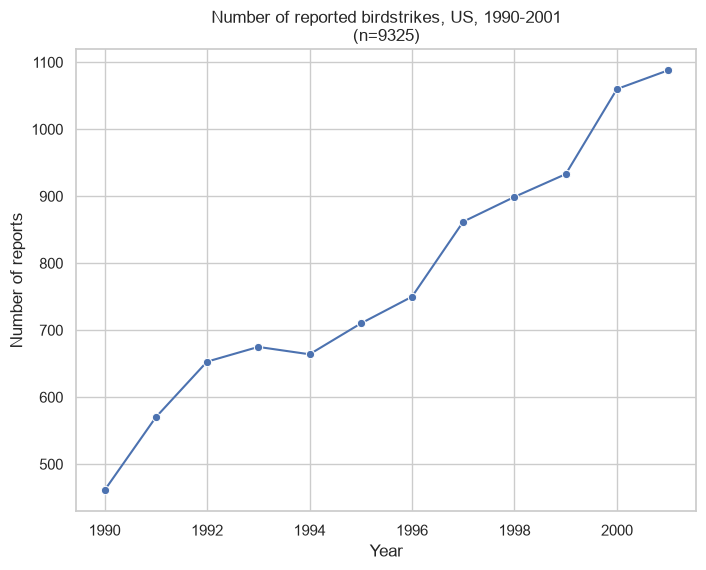

In [186]:
n = (birdstrikes["Flight Date"].dt.year != 2002).sum()

per_year = birdstrikes["Flight Date"].dt.year.value_counts().sort_index()
per_year = per_year[per_year.index != 2002]

fig, ax = plt.subplots(figsize=(8, 6))

sns.lineplot(x=per_year.index, y=per_year.values, marker="o", ax= ax)

ax.set_title(f"Number of reported birdstrikes, US, 1990-2001\n(n={n})")
ax.set_xlabel("Year")
ax.set_ylabel("Number of reports")

fig.savefig('reports_per_year.png', dpi=150, bbox_inches='tight')

plt.show()

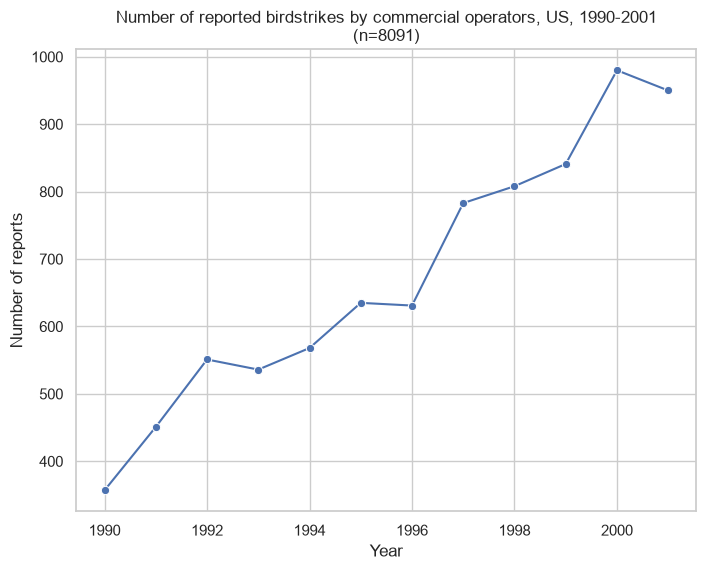

In [187]:
n = ((birdstrikes["Flight Date"].dt.year != 2002) & (birdstrikes["Operation Type"] == "COMMERCIAL")).sum()

per_year = birdstrikes.assign(Year=birdstrikes["Flight Date"].dt.year)

per_year = (per_year[(per_year["Year"] != 2002) & (per_year["Operation Type"] == "COMMERCIAL")]
    .groupby("Year")
    .size()
    .reset_index(name="Number of reports")
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.lineplot(data=per_year, x="Year", y="Number of reports", marker="o", ax=ax)

ax.set_title(f"Number of reported birdstrikes by commercial operators, US, 1990-2001\n(n={n})")
ax.set_xlabel("Year")
ax.set_ylabel("Number of reports")

fig.savefig('reports_commercial_per_year.png', dpi=150, bbox_inches='tight')

plt.show()

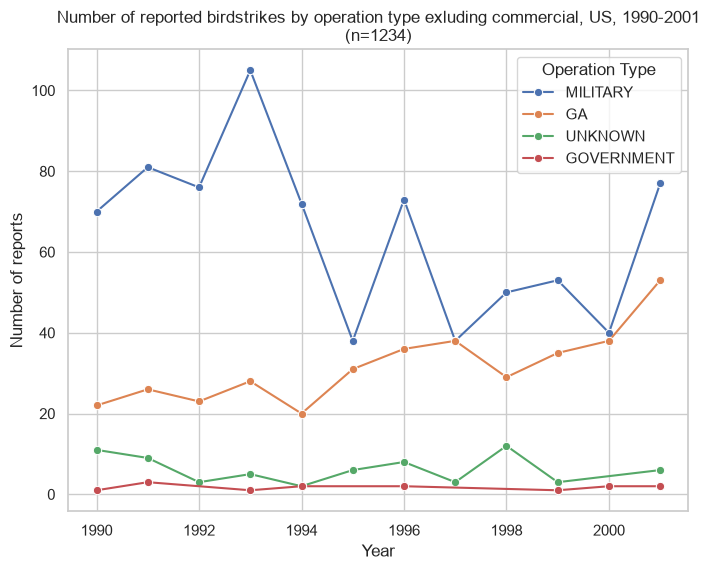

In [188]:
n = ((birdstrikes["Flight Date"].dt.year != 2002) & (birdstrikes["Operation Type"] != "COMMERCIAL")).sum()

h_order = ["MILITARY", "GA", "UNKNOWN", "GOVERNMENT"]

per_year = birdstrikes.assign(Year=birdstrikes["Flight Date"].dt.year)

per_year = (per_year[(per_year["Year"] != 2002) & (per_year["Operation Type"] != "COMMERCIAL")]
    .groupby(["Year", "Operation Type"])
    .size()
    .reset_index(name="Number of reports")
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.lineplot(data=per_year, x="Year", y="Number of reports", hue="Operation Type", hue_order=h_order, marker="o", ax=ax)

ax.set_title(f"Number of reported birdstrikes by operation type exluding commercial, US, 1990-2001\n(n={n})")
ax.set_xlabel("Year")
ax.set_ylabel("Number of reports")

fig.savefig('reports_per_year_not_commercial.png', dpi=150, bbox_inches='tight')

plt.show()

## Number of identified species in birdstrike reports have increased from 1990 to 2001

- 1990 was the lowest mark in the data with 80 reports with the species identified.
- 2001 was the highest with 263 reports with the species identified (2002 is not a full year in the dataset).
- Out of all 9950 reports in the dataset(1990-2002), 1963 have had the species identified.
- When reading the graph one should keep in mind that the number of birdstrik-reports in general has increased over the period(as stated above).

In [189]:
birdstrikes.groupby(birdstrikes["Flight Date"].dt.year)["Species Identified"].sum().sort_index()

Flight Date
1990     80
1991    115
1992     92
1993    106
1994    127
1995    136
1996    134
1997    166
1998    175
1999    187
2000    241
2001    263
2002    141
Name: Species Identified, dtype: int64

In [190]:
print((birdstrikes["Flight Date"].dt.year != 2002).sum())
print(birdstrikes["Species Identified"].sum())

9325
1963


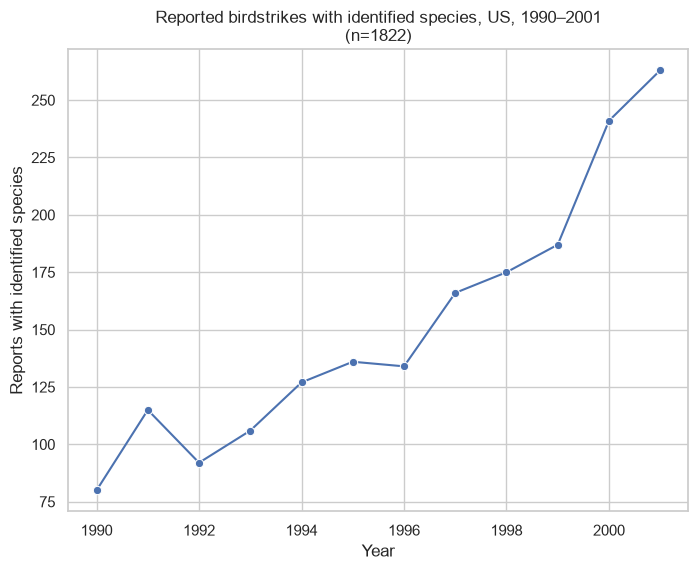

In [191]:
year = birdstrikes["Flight Date"].dt.year

per_year = (
    birdstrikes.loc[year != 2002]
    .groupby(year[year != 2002])["Species Identified"]
    .sum()
    .sort_index()
)

n = per_year.sum()

fig, ax = plt.subplots(figsize=(8, 6))

sns.lineplot(x=per_year.index, y=per_year.values, marker="o", ax=ax)

ax.set_title(f"Reported birdstrikes with identified species, US, 1990–2001\n(n={n})")
ax.set_xlabel("Year")
ax.set_ylabel("Reports with identified species")

fig.savefig('species_reports_per_year.png', dpi=150, bbox_inches='tight')

plt.show()

## There are big differences between states regarding the percentage of birdstrike reports that have identified species (1990-2002).

- On the regional level there is a difference in identified species as a percentage of reports with Northeast 27.1%, Midwest 23.7%, West 22.2% and South 15.4%.
- As for states the largest contributor by identified species as a percentage of reports is Oregon (46.3%), followed by New York (33.8%) and Hawaii (32.2%).
- At the low end of the spectrum we find Arizona (7.2%), Georgia (8.1%) and Utah (9.3%).

In [192]:
(birdstrikes.groupby("Origin State")["Species Identified"]
 .mean()
 .mul(100)
 .reset_index(name="Percent identified")
 .sort_values("Percent identified", ascending=False)
 .round(1).
 head(5))

,Origin State,Percent identified
22,Oregon,46.3
18,New York,33.8
6,Hawaii,32.2
8,Indiana,30.8
17,New Jersey,29.8


In [193]:
(birdstrikes.groupby("Origin State")["Species Identified"]
 .mean()
 .mul(100)
 .reset_index(name="Percent identified")
 .sort_values("Percent identified", ascending=True)
 .round(1)
 .head(5))

,Origin State,Percent identified
0,Arizona,7.2
5,Georgia,8.1
27,Utah,9.3
24,South Carolina,9.8
26,Texas,10.7


In [194]:
(birdstrikes.groupby("Region")["Species Identified"]
 .mean()
 .mul(100)
 .reset_index(name="Percent identified")
 .sort_values("Percent identified", ascending=False)
 .round(1)
 .head(5))

,Region,Percent identified
1,Northeast,27.1
0,Midwest,23.7
3,West,22.2
2,South,15.4


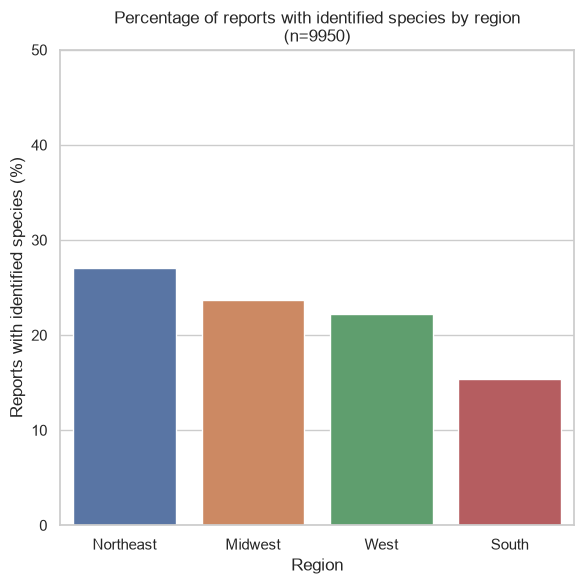

In [195]:
n = len(birdstrikes)

region_percent = (
    birdstrikes.groupby("Region")["Species Identified"]
    .mean()
    .mul(100)
    .reset_index(name="Percent identified")
    .sort_values("Percent identified", ascending=False)
)

fig, ax = plt.subplots(figsize=(6, 6))

sns.barplot(data=region_percent, x="Region", y="Percent identified", hue="Region",ax=ax)

ax.set_title(f"Percentage of reports with identified species by region\n(n={n})")
ax.set_xlabel("Region")
ax.set_ylabel("Reports with identified species (%)")
ax.set_ylim(0, 50)

fig.savefig('species_reports_per_region.png', dpi=150, bbox_inches='tight')

plt.tight_layout()
plt.show()

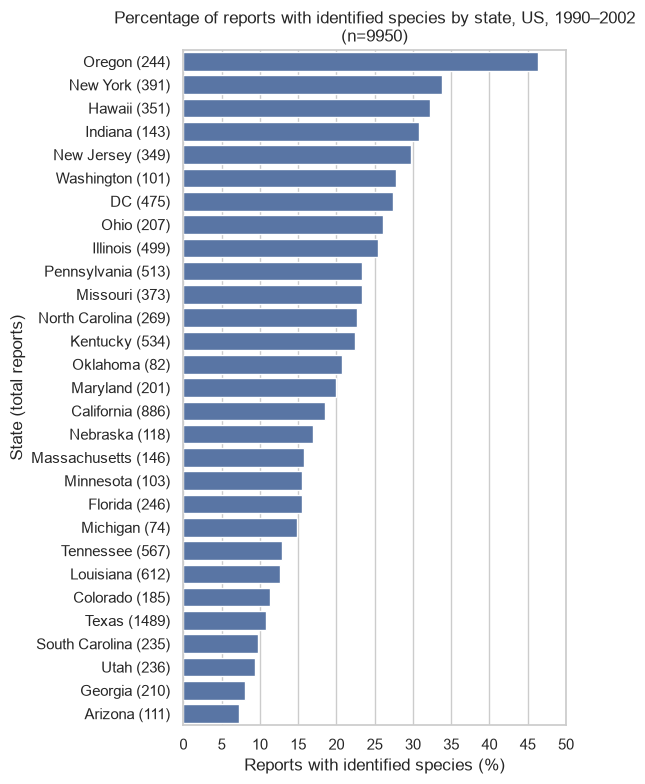

In [196]:
n = len(birdstrikes)

state_percent = (
    birdstrikes.groupby("Origin State")["Species Identified"]
    .mean()
    .mul(100)
    .reset_index(name="Percent identified")
    .sort_values("Percent identified", ascending=False)
)

state_counts = birdstrikes.groupby("Origin State").size()

state_percent["State label"] = (state_percent["Origin State"] +  " (" + state_percent["Origin State"].map(state_counts).astype(str) + ")")

fig, ax = plt.subplots(figsize=(6, 8))

sns.barplot(data=state_percent, y="State label", x="Percent identified", ax=ax)

ax.set_title(f"Percentage of reports with identified species by state, US, 1990–2002\n(n={n})")
ax.set_xlabel("Reports with identified species (%)")
ax.set_ylabel("State (total reports)")
ax.set_xticks([0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50])

fig.savefig('species_reports_per_state.png', dpi=150, bbox_inches='tight')

plt.tight_layout()
plt.show()